# 📉 Polynomial Overfitting & Regularization Rescue (Ridge & Lasso)

An applied experiment demonstrating the **Bias-Variance Tradeoff** on noisy non-linear data ($y = 2\sin(x) + 3 + \epsilon$), identifying the exact **overfitting inflection point** across polynomial degrees 1–15, and rescuing a high-variance degree-12 model using **Ridge (L2)** and **Lasso (L1)** regularization.

---

## 🎯 Experiment Objectives
1. **Synthetic Noisy Curve Generation:** Generate 100 samples from $y = 2\sin(x) + 3 + \epsilon$ (where $\epsilon \sim \mathcal{N}(0, 1)$) and split into training and testing sets.
2. **Bias-Variance Diagnosis (Degrees 1–15):** Fit `PolynomialFeatures` from degree $d = 1$ to $15$ with Ordinary Least Squares (`LinearRegression`) and plot **Train vs. Test RMSE** to pinpoint the exact overfitting inflection point.
3. **Regularization Rescue (Degree 12):** Keep all 12 polynomial features intact and apply standardized **Ridge (L2)** and **Lasso (L1)** pipelines to tame variance, smooth out extreme oscillations, and restore test generalization.

---

## 🧮 Mathematical Intuition

A polynomial model of degree $d$ maps a single input $x$ into a $d$-dimensional feature vector $[x, x^2, x^3, \dots, x^d]$:
$$\hat{y} = w_0 + w_1 x + w_2 x^2 + \dots + w_d x^d$$

As $d$ increases (e.g., $d = 12$), unregularized OLS assigns massive oscillating weights to fit random noise $\epsilon$. Regularization constrains these weights via a penalty term $\lambda \ge 0$:

| Model | Objective Function Minimized | Effect on Degree-12 Polynomial Weights |
| :--- | :--- | :--- |
| **OLS (`LinearRegression`)** | $\frac{1}{m} \sum (y_i - \hat{y}_i)^2$ | Unconstrained; weights explode to memorize noise (High Variance) |
| **Ridge (`L2`)** | $\frac{1}{m} \sum (y_i - \hat{y}_i)^2 + \lambda \sum_{j=1}^{d} w_j^2$ | Shrinks higher-degree weights near zero, smoothing extreme wiggles |
| **Lasso (`L1`)** | $\frac{1}{m} \sum (y_i - \hat{y}_i)^2 + \lambda \sum_{j=1}^{d} |w_j|$ | Drives redundant higher-degree weights to **exact `0.0`** (sparse selection) |

> **Pipeline Note:** Feature scaling (`StandardScaler`) is applied after `PolynomialFeatures(degree=12)` and before `Ridge`/`Lasso` because $x^{12}$ spans a vastly larger numerical range than $x^1$.

---

## 📊 Key Visuals & Verification
- **Plot 1 — Train vs. Test RMSE (Degrees 1–15):** U-shaped validation curve clearly marking the **underfitting zone**, **optimal sweet spot**, and **overfitting inflection point**.
- **Plot 2 — Curve Stabilization Comparison:** Overlay of noisy data points, unregularized Degree-12 OLS fit, and stabilized Degree-12 Ridge (`alpha=1.0`) & Lasso (`alpha=0.01`) curves.
- **Coefficient Inspection:** Side-by-side DataFrame comparison of learned `coef_` arrays proving weight shrinkage (Ridge) and exact zero-sparsity (Lasso) without lowering `degree=12`.

---

## 🛠️ Tech Stack
* **Python 3.x**
* **NumPy & Pandas** (Synthetic sine wave generation & coefficient comparison table)
* **Scikit-Learn** (`PolynomialFeatures`, `StandardScaler`, `Pipeline`, `LinearRegression`, `Ridge`, `Lasso`, `root_mean_squared_error`)
* **Matplotlib** (RMSE inflection curve & polynomial fit visualization)

In [104]:
import numpy as np 
import matplotlib.pyplot as plt
from sklearn.preprocessing import PolynomialFeatures,StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression,Ridge,Lasso
from sklearn.metrics import root_mean_squared_error

In [105]:
X = 5*np.random.rand(100,1) - 2 
Y = 2*np.sin(X) + 3 + np.random.randn(100,1)

In [106]:
X_train,x_test,Y_train,y_test = train_test_split(X,Y,test_size=0.2,random_state=2)

In [107]:
rmse = []
for i in range(1,13):
    
    # getting our polynomial features
    poly = PolynomialFeatures(degree=i)
    X_train_poly = poly.fit_transform(X_train)
    x_test_poly = poly.transform(x_test)
    
    # training our linear model
    lr = LinearRegression()
    lr.fit(X_train_poly,Y_train)
    y_pred = lr.predict(x_test_poly)

    # recorde root mean square error for all degrees
    error = root_mean_squared_error(y_test,y_pred)
    rmse.append(error)

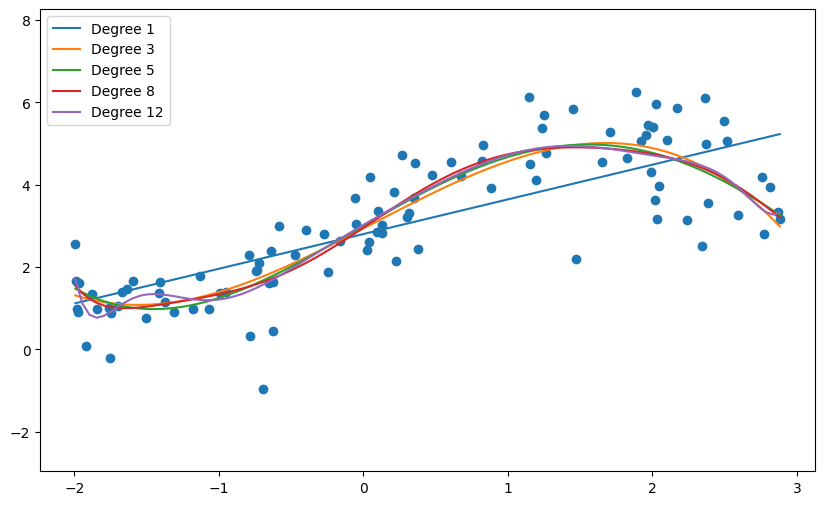

In [108]:
grid = np.linspace(X.min(),X.max(),100).reshape(100,1)

plt.figure(figsize=(10,6))

plt.scatter(X,Y)

for i in [1,3,5,8,12]:
    poly = PolynomialFeatures(degree=i)
    X_train_poly = poly.fit_transform(X_train)
    grid_poly = poly.transform(grid) # testing data
     
    # training our linear model
    lr = LinearRegression()
    lr.fit(X_train_poly,Y_train)
    plt.plot(grid,lr.predict(grid_poly),label=f'Degree {i}')

plt.ylim(Y.min() - 2, Y.max() + 2)  # Prevent high degrees from blowing up the y-axis
plt.legend()
plt.show()

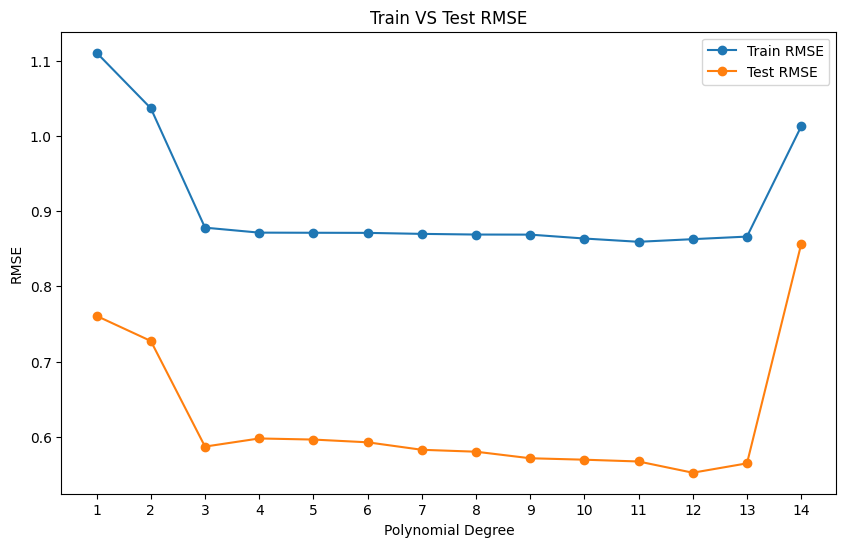

In [109]:
# Train vs Test RMSE Plot

train_rmse = []
test_rmse = []
degrees = range(1,15)

for i in degrees:

    poly = PolynomialFeatures(degree = i)
    X_train_poly = poly.fit_transform(X_train)
    x_test_poly = poly.transform(x_test)

    lr = LinearRegression()
    lr.fit(X_train_poly,Y_train)
    Y_train_pred = lr.predict(X_train_poly)
    y_test_pred = lr.predict(x_test_poly)

    train_error = root_mean_squared_error(Y_train,Y_train_pred)
    test_error = root_mean_squared_error(y_test,y_test_pred)

    train_rmse.append(train_error)
    test_rmse.append(test_error)

plt.figure(figsize=(10,6))
plt.plot(degrees,train_rmse,marker='o',label='Train RMSE')
plt.plot(degrees,test_rmse,marker='o',label='Test RMSE')
plt.xlabel('Polynomial Degree')
plt.ylabel('RMSE')
plt.title('Train VS Test RMSE')
plt.xticks(degrees)
plt.legend()
plt.show()

In [110]:
# How can i keep all 13 features without overfitting !!

In [132]:
ridge_pipe = Pipeline(
    [
        ('poly',PolynomialFeatures(degree=12)),
        ('scaler',StandardScaler()),
        ('ridge',Ridge(alpha=1))
    ]
    )

lasso_pipe = Pipeline(
    [
        ('poly',PolynomialFeatures(degree=12)),
        ('scaler',StandardScaler()),
        ('lasso',Lasso(alpha=0.01))
    ]
    )

In [133]:
ridge_pipe.fit(X_train,Y_train)
ridge_pred = ridge_pipe.predict(x_test)
ridge_rmse = root_mean_squared_error(y_test,ridge_pred)

In [134]:
lasso_pipe.fit(X_train,Y_train)
lasso_pred = lasso_pipe.predict(x_test)
lasso_rmse = root_mean_squared_error(y_test,lasso_pred)

In [135]:
print('Ridge RMSE: ',ridge_rmse)
print('Lasso RMSE: ',lasso_rmse)

Ridge RMSE:  0.6041895580941917
Lasso RMSE:  0.5838308019132854


In [141]:
lr_pipe = Pipeline([
    ('poly',PolynomialFeatures(degree=12)),
    ('scaler',StandardScaler()),
    ('linear_regression',LinearRegression())
])

In [142]:
# Now we have all three Pipeline objects
# lr_pipe
# ridge_pipe
# lasso_pipe

In [143]:
# Lets plot the noisy data points, 
# the wild unregularized Degree-12 OLS fit, 
# and the stabilized Degree-12 Ridge & Lasso fits side-by-side.

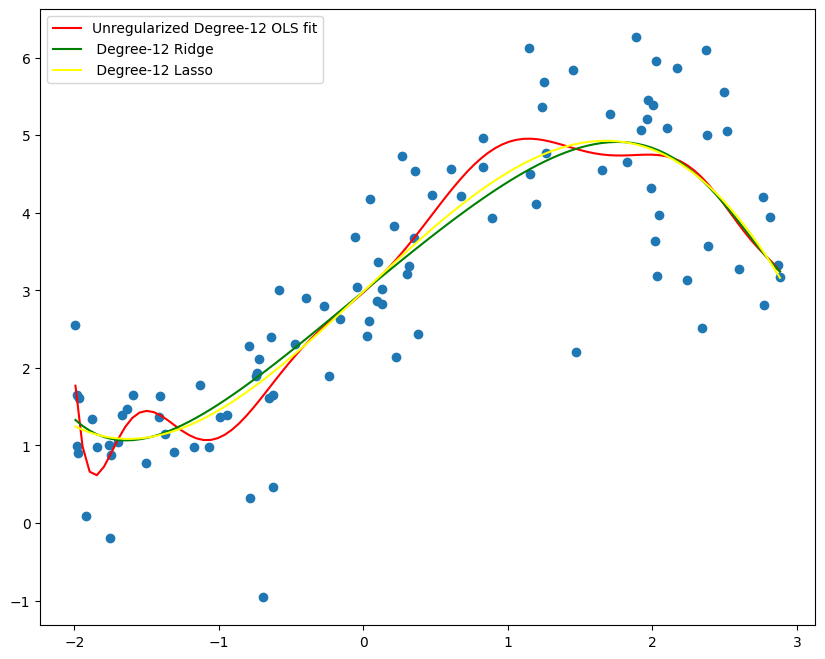

In [144]:
m = np.linspace(X.min(),X.max(),100).reshape(100,1)

lr_pipe.fit(X_train,Y_train)
lr_pred = lr_pipe.predict(m)

ridge_pipe.fit(X_train,Y_train)
ridge_pred = ridge_pipe.predict(m)

lasso_pipe.fit(X_train,Y_train)
lasso_pred = lasso_pipe.predict(m)


plt.figure(figsize=(10,8))

plt.scatter(X,Y)
plt.plot(m,lr_pred,color='red',label='Unregularized Degree-12 OLS fit')
plt.plot(m,ridge_pred,color='green',label=' Degree-12 Ridge')
plt.plot(m,lasso_pred,color='yellow',label=' Degree-12 Lasso')
plt.legend()
plt.show()

In [145]:
import pandas as pd

# Use get_feature_names_out() if you have preprocessing, or X_train.columns if not
feature_names = lr_pipe[:-1].get_feature_names_out() 

coef_df = pd.DataFrame({
    'Feature': feature_names,
    'OLS': lr_pipe[-1].coef_.ravel(),
    'Ridge': ridge_pipe[-1].coef_.ravel(),
    'Lasso': lasso_pipe[-1].coef_.ravel()
})

# Display cleanly in Jupyter
coef_df.round(4)

,Feature,OLS,Ridge,Lasso
0,1,0.0000,0.0000,0.0000
1,x0,2.4600,2.2855,2.5922
2,x0^2,1.5811,-0.0531,0.0000
3,x0^3,11.1488,-0.6685,-1.5398
4,x0^4,-26.1246,0.0655,0.0425
5,x0^5,-83.0048,-0.6575,-0.0000
6,x0^6,165.8479,0.1220,0.0066
7,x0^7,165.6593,-0.3273,0.0000
8,x0^8,-433.9698,0.1458,0.0000
9,x0^9,7.5125,-0.1081,0.0000
